# O que cada reunião diz para o time comercial?
## Bateia — da transcrição à recomendação de ação (Sprint 4)

**Data Science & Statistical Computing — Challenge 2026 FIAP × TOTVS — Sprint 4**

**Grupo:** Enzo Augusto (RM562249) · Gustavo Neres (RM561785) · Rafaell Santiago (RM563486) · Sebastian Iriarte (RM563619)

---

## Resumo do projeto

**Problema.** A TOTVS grava e transcreve milhares de reuniões comerciais por mês, e ninguém consegue ler todas. Nesta sprint juntamos o que construímos nas Sprints 1, 2 e 3 em uma solução que recebe uma transcrição nova e devolve, sozinha, o que interessa para a área comercial: produto citado, sentimento, risco de churn, oportunidade comercial, principais termos e uma recomendação de ação. São as mesmas informações que o app Bateia mostra na tela de cada reunião e na carteira de clientes.

**Base.** As 1.174 transcrições anonimizadas da TOTVS (982 depois da limpeza da Sprint 3). Dessas, 205 têm o campo `TP_RECURSO` do CRM preenchido (lead ou customer), que é o rótulo do modelo de oportunidade.

**Fluxo.** Transcrição → Processamento → Modelo → Indicadores → Recomendação. O processamento reaproveita a limpeza da Sprint 1 e os dicionários da Sprint 2 (revisados aqui); o modelo é a Regressão Logística da Sprint 3; os indicadores e a recomendação são regras simples que usam a própria base como referência.

**Protocolo.** O rótulo `TP_RECURSO` só é usado para escolher o modelo, por validação cruzada nos 75% de treino, e para avaliá-lo uma única vez nos 25% de teste, que ficam guardados até a Parte 5. A limpeza, a revisão dos dicionários e as referências dos indicadores usam apenas o texto das reuniões, nunca o rótulo.

**Resultado.** A Regressão Logística da Sprint 3 continua como modelo de oportunidade. Na validação cruzada ela empata com o Random Forest no F1-macro (0,678 contra 0,676), mas encontra mais oportunidades reais (recall de 0,62 contra 0,58) e varia menos; no teste, o F1-macro foi de 0,606. A solução analisa uma reunião em pouco mais de um décimo de segundo e foi validada em quatro grupos de transcrições novas. A nota de oportunidade ordena bem a fila; já o alerta de churn não reconheceu os trechos de risco que nós anotamos, então ele serve como aviso de leitura, e não como previsão.

**Onde está cada parte**

1. Pipeline completo de processamento
2. Modelo final selecionado e justificativa
3. Sistema de scoring e indicadores
4. Protótipo funcional
5. Validação com novas transcrições
6. Recomendações de negócio
7. Limitações e próximos passos

---

## Bibliotecas e dados

As bibliotecas são as mesmas das sprints anteriores, mais o `joblib` para salvar o modelo, como no CP05.

In [1]:
import json
import os
import re
import string
import unicodedata
import warnings
from collections import Counter
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='viridis')
pd.set_option('display.max_colwidth', 80)

SEMENTE = 42

São quatro arquivos. O `ANON_transcricao.json` é baixado do Google Drive, como na Sprint 1 e 2. Os outros três (o CSV com o `TP_RECURSO`, a base simulada do Challenge e a planilha com os trechos que nós anotamos) estão na pasta do projeto; no Colab, basta arrastá-los para a área de arquivos antes de rodar.

In [2]:
CAMINHO_JSON = 'ANON_transcricao.json'

if not os.path.exists(CAMINHO_JSON):
    !pip install -q gdown
    import gdown
    FILE_ID = '1FQmbrwHWXlh7krfBbR0xFDHoyy3U9fRg'
    gdown.download(f'https://drive.google.com/uc?id={FILE_ID}', CAMINHO_JSON, quiet=False)

arquivos = [CAMINHO_JSON, 'ANON_nome_transcricao.csv',
            'reunioes_transcricoes_mockado.csv', 'anotacao_120_trechos.csv']
for arquivo in arquivos:
    print(arquivo, '->', 'ok' if os.path.exists(arquivo) else 'FALTANDO')

ANON_transcricao.json -> ok
ANON_nome_transcricao.csv -> ok
reunioes_transcricoes_mockado.csv -> ok
anotacao_120_trechos.csv -> ok


### Funções e base da Sprint 3

As stopwords, a limpeza do texto, a recuperação do `TP_RECURSO` e a remoção de duplicatas são exatamente as da Sprint 3. A única coluna nova é a transcrição original (`TRANSCRICAO`), com as marcações `[LOCUTOR n]`, que vamos precisar para medir a conversa.

In [3]:
STOPWORDS_PT = set("""
a a ao aos aquela aquelas aquele aqueles aquilo as ate com como da das de dela
delas dele deles depois do dos e ela elas ele eles em entre era eram essa essas
esse esses esta estas este estes estou esta estamos estao eu foi fomos for
foram fosse fui ha isso isto ja lhe lhes mais mas me mesmo meu meus minha minhas
muito na nas nem no nos nos nossa nossas nosso nossos num numa nao o os ou para
pela pelas pelo pelos por qual quando que quem se seu seus so sua suas tambem
te tem tem temos tendo tenho ter teu teus teve tinha tive tivemos tu tua tuas
um uma voce voces sera serao seria seriam sendo onde la aqui ali entao agora
ainda assim bem cada
locutor pessoa empresa local ne ta ok pra pro tipo assim entao ai ali ola
oi tudo bem obrigado obrigada beleza show certo perfeito legal ah eh hum hmm
gente cara coisa coisas vamos vou vai vao fazer fazendo feito acho achar
bom dia boa tarde boa noite horas mail ano anos mil hoje ontem amanha agora
momento momentinho
""".split())


def limpar_transcricao(texto):
    t = re.sub(r'\[LOCUTOR\s*\d+\]:?', ' ', texto)
    t = re.sub(r'\[(PESSOA|EMPRESA|LOCAL)\]', ' ', t)
    t = t.lower()
    t = re.sub(f'[{re.escape(string.punctuation)}]', ' ', t)
    t = re.sub(r'\b\d+\b', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t


def remover_stopwords(texto, stopwords=STOPWORDS_PT, min_len=3):
    palavras = [p for p in texto.split() if p not in stopwords and len(p) >= min_len]
    return ' '.join(palavras)


def pipeline_limpeza(texto):
    return remover_stopwords(limpar_transcricao(texto))


def remove_acentos(s):
    return ''.join(ch for ch in unicodedata.normalize('NFD', s)
                   if unicodedata.category(ch) != 'Mn')

In [4]:
registros = []
with open(CAMINHO_JSON, encoding='utf-8') as f:
    for linha in f:
        linha = linha.strip()
        if linha:
            registros.append(json.loads(linha))

df = pd.DataFrame([{
    'ID_MEETING':    int(r['ID_MEETING']),
    'CODT':          (r.get('CODT') or '').strip(),
    'NOME_SEGMENTO': r.get('NOME_SEGMENTO') or 'Sem segmento',
    'TRANSCRICAO':   r.get('ANON_TRANSCRICAO') or '',
} for r in registros])
df['TEXTO_LIMPO'] = df['TRANSCRICAO'].apply(pipeline_limpeza)
df['N_LOCUTORES'] = df['TRANSCRICAO'].apply(lambda t: len(set(re.findall(r'\[LOCUTOR (\d+)\]', t))))

# TP_RECURSO recuperado do CSV por expressão regular (Sprint 3)
INICIO_REGISTRO = re.compile(r'"(\d{6,8}),(\d{4}-\d{2}-\d{2}[^,]*),' + r'([^,]*),' * 6)
conteudo_csv = open('ANON_nome_transcricao.csv', encoding='latin1').read()
metadados = pd.DataFrame([{'ID_MEETING': int(m.group(1)), 'TP_RECURSO': m.group(8).strip()}
                          for m in INICIO_REGISTRO.finditer(conteudo_csv)]).drop_duplicates('ID_MEETING')

# mesma limpeza da Sprint 3: IDs repetidos, textos idênticos e textos muito curtos
base = df.drop_duplicates('ID_MEETING').drop_duplicates('TEXTO_LIMPO')
base = base[base['TEXTO_LIMPO'].apply(len) >= 200].reset_index(drop=True)
base = base.merge(metadados, on='ID_MEETING', how='left')
base['oportunidade'] = base['TP_RECURSO'].map({'lead': 'Oportunidade', 'customer': 'Não oportunidade'})

rotuladas = base[base['oportunidade'].notna()].reset_index(drop=True)
sem_rotulo = base[base['oportunidade'].isna()].reset_index(drop=True)

print('Reuniões no arquivo:', len(df))
print('Base limpa:', len(base), '| com rótulo:', len(rotuladas), '| sem rótulo:', len(sem_rotulo))
print(rotuladas['oportunidade'].value_counts())

Reuniões no arquivo: 1174
Base limpa: 982 | com rótulo: 205 | sem rótulo: 777
oportunidade
Não oportunidade    116
Oportunidade         89
Name: count, dtype: int64


---

## Parte 1 — Pipeline completo de processamento

Toda transcrição nova passa pelo mesmo caminho:

1. **Texto para o modelo:** a limpeza da Sprint 1 (minúsculas, sem pontuação, números e stopwords). O modelo foi treinado com esse texto, então precisa receber igual.
2. **Texto para busca:** a mesma limpeza, mas sem acento e mantendo as stopwords. Expressões como "não renovar" ou "a Senior" perdem o sentido sem elas.
3. **Estrutura da conversa:** quantas palavras cada locutor falou, quantas perguntas foram feitas e quantos locutores aparecem.
4. **Dicionários:** produtos TOTVS, concorrentes, sinais de churn, sinais de expansão e palavras de sentimento.
5. **Modelo:** probabilidade de a reunião ser uma oportunidade comercial.
6. **Indicadores e recomendação:** Partes 3 e 4.

### Revisão dos dicionários da Sprint 2

Antes de usar os dicionários da Sprint 2 dentro da solução, conferimos como eles se comportam na base. Essa revisão olha só o texto das reuniões; o rótulo do CRM não entra em nenhuma decisão de dicionário. A célula abaixo compara, para alguns termos, a porcentagem de reuniões encontrada pela busca que usávamos (o termo como pedaço do texto com acento) e pela busca por palavra inteira (`\b`) no texto sem acento.

In [5]:
def texto_para_busca(texto):
    return remove_acentos(limpar_transcricao(texto))


def contar_termos(texto_busca, termos):
    # devolve só os termos encontrados, com o número de vezes que cada um aparece
    encontrados = {}
    for termo in termos:
        n = len(re.findall(r'\b' + termo + r'\b', texto_busca))
        if n > 0:
            encontrados[termo] = n
    return encontrados


base['TEXTO_BUSCA'] = base['TRANSCRICAO'].apply(texto_para_busca)

linhas = []
for termo in ['sap', 'rm', 'insatisfacao', 'reclamacao', 'totos', 'trocar',
              'migracao', 'rescisao', 'oracle', 'senior', 'problema', 'modulo']:
    busca_antiga = base['TEXTO_LIMPO'].apply(lambda t: termo in t).mean()
    palavra_inteira = base['TEXTO_BUSCA'].apply(lambda t: len(contar_termos(t, [termo])) > 0).mean()
    linhas.append({'termo': termo, '% busca antiga': 100 * busca_antiga,
                   '% palavra inteira': 100 * palavra_inteira})

pd.DataFrame(linhas).round(1)

,termo,% busca antiga,% palavra inteira
0,sap,52.6,0.0
1,rm,97.4,25.6
2,insatisfacao,0.0,3.0
3,reclamacao,0.0,4.2
4,totos,54.2,53.8
5,trocar,40.2,39.2
6,migracao,0.0,17.4
7,rescisao,0.0,3.8
8,oracle,7.8,7.8
9,senior,1.7,4.7


A busca antiga encontrava "sap" em mais da metade das reuniões; com palavra inteira, em nenhuma. Eram todas "whatsapp". O mesmo acontecia com "rm", que aparecia dentro de qualquer palavra (97% das reuniões contra 26%). No sentido contrário, "insatisfação", "reclamação", "migração" e "rescisão" nunca eram encontradas, porque o texto tem acento e o dicionário não.

Os termos que continuam frequentes mesmo com palavra inteira precisam ser lidos no contexto. A função `trecho` pega as 15 palavras antes e depois de um termo, e a `mostrar_contexto` usa ela para mostrar dois trechos reais de cada um.

In [6]:
def trecho(texto_busca, termo):
    # o termo com até 15 palavras antes e depois, como evidência do sinal
    achados = re.findall(r'(?:\S+ ){0,15}\b' + termo + r'\b(?: \S+){0,15}', texto_busca)
    if not achados:
        return ''
    return '...' + achados[0] + '...'


def mostrar_contexto(termo, n=2):
    print('--', termo)
    mostrados = 0
    for t in base['TEXTO_BUSCA']:
        achado = trecho(t, termo)
        if achado:
            print('  ', achado)
            mostrados += 1
        if mostrados == n:
            break


for termo in ['trocar', 'migracao', 'rescisao', 'oracle', 'senior']:
    mostrar_contexto(termo)

-- trocar
   ...tudo em casa ne ja fui da ja fui da rm tambem esquenta nao pode trocar eu sei que e horrivel eu sei que e horrivel a gente nao faz isso...
   ...porque o nosso sistema hoje e interno e tinha pessoas torcendo contra nao nao vamos trocar esta funcionando e um custo para a empresa entao a gente precisa fazer dar certo...
-- migracao
   ...ne mas agora vai ne e o que aconteceu ainda estamos naquela segunda fase da migracao a gente migrou os postos la eu tava ate comentando ne comentou e ai agora...
   ...hoje nessa atualizacao global muito veloz e traze los a importancia de participar de uma migracao dessa de uma troca de sistema desse porte tambem e importante para buscar o engajamento...
-- rescisao


   ...que ele esta com alto risco de desligamento alto desligamento ele esta com probabilidade de rescisao esta pensando ja em pedir demissao ta e como e que o sistema sabe disso...


   ...executar aqui o calculo de ferias desse colaborador eu posso estar executando o calculo de rescisao para este colaborador tambem entao e algo que eu consigo ja de uma unica rotina...
-- oracle


   ...acho que se seguir o mesmo caminho que tem ali do sql server e do oracle e o que a gente precisa ne um backup diario depois mais um backup mensal...


   ...na hora isso ai e que name que voces usam gente utiliza tanto server quanto oracle ta voce pode opcionalmente migrar vindo para a oracle e muito mais complexo e fica...
-- senior


   ...o que a gente precisa e resolver a parte da reforma tributaria que a troca senior nos atenderia e ai a gente precisa focar de novo no nosso negocio olhar para...


   ...voces conseguem colocar aqui o cargo unidade sindicato departamento niveis hierarquicos entao medico junior pleno senior podem colocar aqui tambem detalhes desse nivel responsabilidades requisitos competencias enfim deixar aqui todo o...


A leitura confirmou o que os números sugeriam, e os dicionários mudaram assim:

- **trocar** aparece como "trocar ideias", "trocar o status"; **migração** é a migração de dados da própria implantação TOTVS. Os dois saíram dos sinais de churn.
- **rescisão** é quase sempre a rescisão trabalhista calculada no módulo de Folha. Saiu dos sinais de churn ("rescindir" ficou).
- **oracle** é o banco de dados usado junto com o Protheus, e não um ERP concorrente. Saiu dos concorrentes.
- **senior** aparece muito como cargo ("pleno e sênior"). Agora só conta quando vem com artigo ("a Senior", "da Senior"), que é como se fala da empresa.
- **totos** é a própria TOTVS mal transcrita, como já tínhamos visto na Sprint 1, e não identifica produto. Saiu dos produtos, junto com "totvs".
- **problema** aparece em 79% das reuniões e **módulo** em 45%. Pela mesma lógica do `max_df=0.6` do TF-IDF, uma palavra presente em quase toda reunião não diferencia nada. "Problema" saiu das palavras negativas e "módulo" foi trocado por expressões de expansão ("novo módulo", "mais licenças").

Também acrescentamos expressões de churn mais específicas, como "cancelar o contrato", "não renovar" e "outro fornecedor".

In [7]:
PRODUTOS_TOTVS = {'Protheus': ['protheus', 'proteus', 'microsiga'], 'RM': ['rm'],
                  'Fluig': ['fluig'], 'Datasul': ['datasul'], 'Winthor': ['winthor'],
                  'Consinco': ['consinco']}

CONCORRENTES = {'SAP': ['sap'], 'Senior': ['(?:a|da|na|do|no|pela|com|para|pra) senior'],
                'Sankhya': ['sankhya'], 'Linx': ['linx'], 'Omie': ['omie'], 'Bling': ['bling'],
                'Conta Azul': ['conta azul'], 'Microsoft Dynamics': ['dynamics']}

SINAIS_CHURN = ['cancelar o contrato', 'cancelamento do contrato', 'cancelamento', 'rescindir',
                'nao renovar', 'encerrar o contrato', 'insatisfeito', 'insatisfeitos',
                'insatisfacao', 'reclamacao', 'reclamar', 'reclamando', 'muito caro',
                'outro fornecedor', 'concorrente']

SINAIS_EXPANSAO = ['novo modulo', 'outro modulo', 'mais licencas', 'licencas adicionais',
                   'upgrade', 'expandir', 'ampliar', 'contratar']

PALAVRAS_POSITIVAS = ['otimo', 'otima', 'excelente', 'maravilha', 'maravilhoso', 'gostei',
                      'adorei', 'satisfeito', 'satisfeitos', 'parabens', 'facilitou',
                      'resolveu', 'resolvido', 'agradeco', 'sucesso', 'bacana']

PALAVRAS_NEGATIVAS = ['problemas', 'ruim', 'pessimo', 'dificil', 'dificuldade', 'demora',
                      'demorado', 'atraso', 'atrasado', 'erro', 'erros', 'falha', 'travando',
                      'travou', 'insatisfeito', 'insatisfacao', 'frustrado', 'frustracao',
                      'caro', 'complicado', 'preocupado', 'preocupacao', 'reclamacao',
                      'reclamar', 'reclamando', 'nao funciona']

PROXIMOS_PASSOS = ['proxima reuniao', 'proximos passos', 'agendar', 'agendamos', 'proposta',
                   'retorno', 'enviar', 'envio', 'cronograma', 'prazo', 'combinado', 'marcar',
                   'follow up']

### Funções de extração

A função `identificar` devolve os nomes de um dicionário que aparecem no texto, e `valores_citados` pega os valores em reais falados na reunião. A `trecho`, definida acima, mostra as palavras em volta de um termo, que é o que o app exibe como evidência de cada sinal.

A função `medir_conversa` usa as marcações `[LOCUTOR n]`. Antes, troca `[PESSOA]`, `[EMPRESA]` e `[LOCAL]` por uma palavra qualquer, porque essas marcações também usam colchetes e cortariam a fala no meio. Depois, soma as palavras de cada locutor e calcula as quatro medidas que entram no ITA (Parte 3):

- **perguntas:** pontos de interrogação a cada mil palavras;
- **balanço de fala:** 1 quando os dois locutores que mais falaram dividem a fala meio a meio, 0 quando um deles fala tudo;
- **engajamento:** a parte da conversa que não ficou com o locutor que mais falou;
- **próximos passos:** termos de encaminhamento ("proposta", "agendar", "retorno"...) nos últimos 20% da reunião.

In [8]:
def identificar(texto_busca, dicionario):
    return [nome for nome, variacoes in dicionario.items() if contar_termos(texto_busca, variacoes)]


def valores_citados(transcricao):
    return sorted(set(re.findall(r'R\$ ?\d+(?:[.,]\d+)*(?: mil| milhões)?', transcricao)))


def medir_conversa(transcricao):
    texto = re.sub(r'\[(PESSOA|EMPRESA|LOCAL)\]', 'x', transcricao)
    falas = re.findall(r'\[LOCUTOR (\d+)\]:?([^\[]*)', texto)
    palavras_por_locutor = Counter()
    for locutor, fala in falas:
        palavras_por_locutor[locutor] += len(fala.split())

    palavras = texto_para_busca(transcricao).split()
    n_palavras = max(len(palavras), 1)
    perguntas = transcricao.count('?') / n_palavras * 1000

    maiores = palavras_por_locutor.most_common(2)
    total = sum(palavras_por_locutor.values())
    if len(maiores) == 2:
        balanco = 1 - abs(maiores[0][1] / (maiores[0][1] + maiores[1][1]) - 0.5) * 2
    else:
        balanco = 0
    engajamento = 1 - maiores[0][1] / total if total > 0 else 0

    final = ' '.join(palavras[int(len(palavras) * 0.8):])
    proximos = sum(contar_termos(final, PROXIMOS_PASSOS).values())

    return {'perguntas': perguntas, 'balanco': balanco, 'engajamento': engajamento,
            'proximos_passos': proximos, 'n_locutores': len(palavras_por_locutor)}


exemplo = base.iloc[0]
print('Produtos:', identificar(exemplo['TEXTO_BUSCA'], PRODUTOS_TOTVS))
print('Concorrentes:', identificar(exemplo['TEXTO_BUSCA'], CONCORRENTES))
print('Valores citados:', valores_citados(exemplo['TRANSCRICAO']))
print('Sinais de churn:', contar_termos(exemplo['TEXTO_BUSCA'], SINAIS_CHURN))
print('Medidas da conversa:', {k: round(v, 2) for k, v in medir_conversa(exemplo['TRANSCRICAO']).items()})

Produtos: ['RM']
Concorrentes: []
Valores citados: ['R$ 0,67']
Sinais de churn: {}
Medidas da conversa: {'perguntas': 26.25, 'balanco': 0.96, 'engajamento': 0.63, 'proximos_passos': 11, 'n_locutores': 59}


Com os dicionários revisados, contamos em quantas reuniões aparece cada produto e cada concorrente.

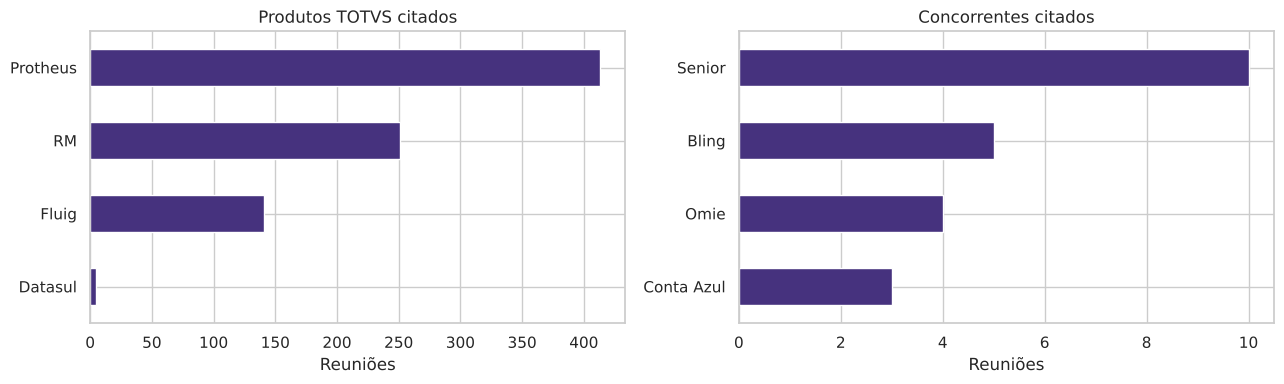

Produtos: {'Protheus': 413, 'RM': 251, 'Fluig': 141, 'Datasul': 5}
Concorrentes: {'Senior': 10, 'Bling': 5, 'Omie': 4, 'Conta Azul': 3}


In [9]:
produtos = Counter(p for t in base['TEXTO_BUSCA'] for p in identificar(t, PRODUTOS_TOTVS))
concorrentes = Counter(c for t in base['TEXTO_BUSCA'] for c in identificar(t, CONCORRENTES))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(produtos).sort_values().plot(kind='barh', ax=ax[0])
ax[0].set_title('Produtos TOTVS citados')
ax[0].set_xlabel('Reuniões')
pd.Series(concorrentes).sort_values().plot(kind='barh', ax=ax[1])
ax[1].set_title('Concorrentes citados')
ax[1].set_xlabel('Reuniões')
plt.tight_layout()
plt.show()

print('Produtos:', dict(produtos.most_common()))
print('Concorrentes:', dict(concorrentes.most_common()))

O Protheus aparece em 413 das 982 reuniões, quase sempre transcrito como "proteus", seguido do RM (251) e do Fluig (141). Concorrentes quase não aparecem: o mais citado, a Senior, está em 10 reuniões. Isso corrige a conclusão da Sprint 2 de que o SAP seria o concorrente mais citado, que vinha toda do "whatsapp".

### Principais termos da reunião

Para resumir o assunto da reunião usamos o TF-IDF com os mesmos parâmetros da Sprint 2, ajustado nas 982 reuniões. Os termos de maior peso em uma transcrição são os que ela usa muito e que aparecem pouco nas outras, ou seja, o que aquela conversa tem de característico.

In [10]:
tfidf_termos = TfidfVectorizer(max_features=400, min_df=8, max_df=0.6, ngram_range=(1, 2))
tfidf_termos.fit(base['TEXTO_LIMPO'])
vocabulario = tfidf_termos.get_feature_names_out()


def principais_termos(texto_limpo, n=8):
    # mesmo cálculo de pesos da Sprint 2, aplicado a uma reunião só
    pesos = np.asarray(tfidf_termos.transform([texto_limpo]).sum(axis=0)).flatten()
    termos = pd.Series(pesos, index=vocabulario).sort_values(ascending=False).head(n)
    return list(termos[termos > 0].index)


for i in range(3):
    r = base.iloc[i]
    print(r['ID_MEETING'], r['NOME_SEGMENTO'], '->', ', '.join(principais_termos(r['TEXTO_LIMPO'])))

1247082 SAUDE -> gestor, médico, portal, funcionário, férias, relatório, equipe, colaborador
989351 SAUDE -> horário, colaborador, banco, jornada, portal, saldo, dentro sistema, folha
1027294 Sem segmento -> colaborador, colaboradores, gestor, dentro sistema, folha, aplicativo, relatório, horário


---

## Parte 2 — Modelo final selecionado e justificativa

Na Sprint 3 comparamos Regressão Logística e Random Forest para classificar a reunião como oportunidade comercial (lead) ou não (customer). Os hiperparâmetros escolhidos pelo `GridSearchCV` foram `C=5` na Regressão Logística e 300 árvores sem limite de profundidade no Random Forest. Aqui usamos esses mesmos valores.

**Protocolo.** O `TP_RECURSO` é a resposta que o modelo tenta prever, então ele só pode aparecer em três momentos, nesta ordem. Primeiro, separamos 25% das 205 reuniões rotuladas como teste, com a mesma semente e a mesma estratificação da Sprint 3; esse teste fica guardado até a Parte 5. Depois, escolhemos o modelo só com os outros 75%, por validação cruzada estratificada de 5 folds. Por último, avaliamos o modelo escolhido uma única vez no teste e só então treinamos a versão final com as 205. Nada antes disso usa o rótulo: a limpeza, a revisão dos dicionários (Parte 1) e as referências dos indicadores (Parte 3) olham apenas o texto das reuniões.

Além do F1-macro, olhamos o recall da classe "Oportunidade": na Sprint 3 definimos que deixar passar uma oportunidade real é o erro mais caro para o vendedor. Para o `cross_val_score` calcular esse recall, a classe vira um número (1 para "Oportunidade" e 0 para "Não oportunidade") só dentro desta comparação.

In [11]:
def montar_pipeline(classificador):
    # TF-IDF com os parâmetros da Sprint 2 + classificador (mesmo pipeline da Sprint 3)
    return Pipeline([
        ('tfidf', TfidfVectorizer(max_features=400, min_df=8, max_df=0.6, ngram_range=(1, 2))),
        ('clf', classificador),
    ])


def criar_modelo(nome):
    if nome == 'Regressão Logística':
        return LogisticRegression(C=5, max_iter=3000, class_weight='balanced', random_state=SEMENTE)
    if nome == 'Random Forest':
        return RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=1,
                                      max_features='sqrt', class_weight='balanced',
                                      n_jobs=-1, random_state=SEMENTE)
    return DummyClassifier(strategy='most_frequent')


X = rotuladas['TEXTO_LIMPO']
y = rotuladas['oportunidade']

# o teste fica guardado até a Parte 5
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25,
                                                        random_state=SEMENTE, stratify=y)
y_treino_num = (y_treino == 'Oportunidade').astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

linhas = []
for nome in ['Baseline', 'Regressão Logística', 'Random Forest']:
    f1 = cross_val_score(montar_pipeline(criar_modelo(nome)), X_treino, y_treino_num,
                         cv=cv, scoring='f1_macro')
    recall = cross_val_score(montar_pipeline(criar_modelo(nome)), X_treino, y_treino_num,
                             cv=cv, scoring='recall')
    linhas.append({'Modelo': nome, 'F1-macro (média)': f1.mean(), 'F1-macro (desvio)': f1.std(),
                   'Recall Oportunidade (média)': recall.mean(), 'Recall Oportunidade (desvio)': recall.std()})

print('Treino:', len(X_treino), 'reuniões | teste guardado:', len(X_teste), 'reuniões')
pd.DataFrame(linhas).round(3)

Treino: 153 reuniões | teste guardado: 52 reuniões


,Modelo,F1-macro (média),F1-macro (desvio),Recall Oportunidade (média),Recall Oportunidade (desvio)
0,Baseline,0.362,0.005,0.000,0.000
1,Regressão Logística,0.678,0.047,0.620,0.074
2,Random Forest,0.676,0.077,0.575,0.153


O baseline fica em 0,362, porque sempre responde a classe maior. No F1-macro, a Regressão Logística (0,678) e o Random Forest (0,676) empatam: a diferença é muito menor que o desvio entre os folds. O desempate vem do que importa para o vendedor. A Regressão Logística encontra mais oportunidades reais (recall médio de 0,620 contra 0,575) e é bem mais estável entre os folds: o desvio do recall do Random Forest (0,153) é o dobro do dela (0,074), ou seja, dependendo das reuniões que caem em cada parte, ele ora acha a maioria das oportunidades, ora perde boa parte delas.

**Modelo final: Regressão Logística.** Com o mesmo F1-macro, ela deixa passar menos oportunidades, e esse foi o erro que definimos como mais caro na Sprint 3: uma oportunidade que o modelo não marca simplesmente não aparece na fila, enquanto um alarme falso o vendedor descarta em um minuto. Ela também mostra, pelos coeficientes, quais termos puxaram a decisão, o que ajuda a explicar ao vendedor por que a reunião foi marcada, e é bem mais leve para rodar dentro do app. O F1-macro de 0,678 é o mesmo que a validação cruzada da Sprint 3 deu para `C=5`, o que confirma que o procedimento foi repetido igual.

**Treino final.** O teste da Parte 5 avalia o modelo treinado só com as 153 reuniões de treino. Para usar na solução, treinamos depois com todas as 205, mantendo `C=5`; mais exemplos deixam o modelo um pouco mais estável, e a avaliação continua valendo porque o procedimento é o mesmo. Como na Sprint 3, os coeficientes mostram quais termos puxam a decisão para cada lado (positivo puxa para "Oportunidade").

In [12]:
modelo_final = montar_pipeline(criar_modelo('Regressão Logística')).fit(X, y)

coeficientes = pd.Series(modelo_final.named_steps['clf'].coef_[0],
                         index=modelo_final.named_steps['tfidf'].get_feature_names_out())
print('Classes do modelo:', list(modelo_final.classes_))
pd.DataFrame({
    'Puxam para Oportunidade': coeficientes.sort_values(ascending=False).head(10).index,
    'peso (+)': coeficientes.sort_values(ascending=False).head(10).values.round(2),
    'Puxam para Não oportunidade': coeficientes.sort_values().head(10).index,
    'peso (-)': coeficientes.sort_values().head(10).values.round(2),
})

Classes do modelo: ['Não oportunidade', 'Oportunidade']


,Puxam para Oportunidade,peso (+),Puxam para Não oportunidade,peso (-)
0,paciente,2.27,histórico,-2.10
1,compra,2.09,pacote,-1.94
2,estoque,1.97,verificar,-1.84
3,contabilidade,1.97,financeiro,-1.74
4,gestão,1.94,contrato,-1.68
5,comentei,1.85,mercado,-1.59
6,portal,1.79,dezembro,-1.58
7,período,1.78,integração,-1.54
8,deixa ver,1.67,linha,-1.54
9,validação,1.61,api,-1.47


Os termos que puxam para oportunidade descrevem a operação do cliente (estoque, compra, gestão, contabilidade), que é o assunto de quem ainda está conhecendo o negócio numa prospecção. Os que puxam para não oportunidade são de quem já tem contrato: histórico, pacote, contrato, integração, API. "Paciente" no topo mostra que parte da decisão vem do segmento do cliente, e não da conversa; voltamos a isso nas limitações.

O modelo foi salvo com `joblib` mais abaixo, junto com os outros arquivos do app.

---

## Parte 3 — Sistema de scoring e indicadores

Além da oportunidade, que vem do modelo, a solução calcula o sentimento, o risco de churn, o ITA (Índice de Trusted Advisor) e o selo de confiança. Nenhum deles tem rótulo na base para treinar um modelo (não existe, por exemplo, uma coluna dizendo quais clientes cancelaram), então são regras simples. Para não inventar números, toda referência vem da própria base: quartis, percentis e o limite de outlier da Sprint 2.

Todos os indicadores usam a mesma escala de 0 a 100 do app Bateia, e a célula abaixo calcula as medidas brutas de todas as reuniões, que servem de referência.

In [13]:
def pontuar_sentimento(texto_busca):
    positivas = sum(contar_termos(texto_busca, PALAVRAS_POSITIVAS).values())
    negativas = sum(contar_termos(texto_busca, PALAVRAS_NEGATIVAS).values())
    if positivas + negativas == 0:
        return 0
    return (positivas - negativas) / (positivas + negativas)


medidas = pd.DataFrame([medir_conversa(t) for t in base['TRANSCRICAO']])
medidas['sentimento'] = base['TEXTO_BUSCA'].apply(pontuar_sentimento)
medidas['sinais_churn'] = base['TEXTO_BUSCA'].apply(lambda t: sum(contar_termos(t, SINAIS_CHURN).values()))
medidas.describe().round(2)

,perguntas,balanco,engajamento,proximos_passos,n_locutores,sentimento,sinais_churn
count,982.00,982.00,982.00,982.00,982.00,982.00,982.00
mean,20.77,0.58,0.43,3.08,21.62,-0.19,0.86
std,8.06,0.28,0.19,3.33,17.80,0.55,2.03
min,0.00,0.00,0.00,0.00,0.00,-1.00,0.00
25%,15.57,0.37,0.32,1.00,9.00,-0.62,0.00
50%,19.55,0.63,0.46,2.00,18.00,-0.23,0.00
75%,25.04,0.83,0.57,4.00,31.00,0.13,1.00
max,83.33,1.00,0.81,35.00,179.00,1.00,25.00


**Sentimento.** A pontuação compara as palavras positivas e negativas da reunião:

$$\text{sentimento} = \frac{\text{positivas} - \text{negativas}}{\text{positivas} + \text{negativas}}$$

Ela vai de -1 (só palavras negativas) a +1 (só positivas). Em reunião comercial é normal o cliente falar de dificuldades, porque é assim que ele explica o que quer resolver; por isso o corte não é o zero. A reunião é comparada com as outras da base: abaixo do 1º quartil é **Negativo**, acima do 3º quartil é **Positivo** e o resto é **Neutro**.

**Risco de churn.** Contamos os sinais de churn da reunião. A maioria das reuniões não tem nenhum, então a nota de risco chega a 100 quando a reunião passa do percentil 90 da base; abaixo disso, ganha a proporção correspondente. Nota 100 é risco **Alto**, qualquer sinal é **Atenção** e nenhum sinal é **Sem sinais**.

**ITA.** Cada uma das quatro medidas da conversa vira uma nota de 0 a 100, comparando com o 3º quartil da base: a reunião que chega no 3º quartil tira 100 naquele critério. O ITA é a média dos quatro critérios.

**Selo de confiança.** Vem da análise de diarização da Sprint 2: acima do limite de outlier de locutores (IQR), ou sem nenhuma marcação de locutor, o selo é **Baixa**; acima do 3º quartil, **Média**; nos outros casos, **Alta**.

In [14]:
SENT_Q1, SENT_Q3 = medidas['sentimento'].quantile([0.25, 0.75])
LIMITE_CHURN = int(medidas['sinais_churn'].quantile(0.90)) + 1
REFERENCIA_ITA = {c: medidas[c].quantile(0.75) for c in ['perguntas', 'balanco', 'engajamento', 'proximos_passos']}
q1_loc, q3_loc = base['N_LOCUTORES'].quantile([0.25, 0.75])
LIMITE_OUTLIER = q3_loc + 1.5 * (q3_loc - q1_loc)

print('Sentimento: 1º quartil =', round(SENT_Q1, 2), '| 3º quartil =', round(SENT_Q3, 2))
print('Risco de churn: nota 100 a partir de', LIMITE_CHURN, 'sinais')
print('Referências do ITA (3º quartil):', {c: round(float(v), 2) for c, v in REFERENCIA_ITA.items()})
print('Locutores: 3º quartil =', q3_loc, '| limite de outlier =', LIMITE_OUTLIER)

Sentimento: 1º quartil = -0.62 | 3º quartil = 0.13
Risco de churn: nota 100 a partir de 3 sinais
Referências do ITA (3º quartil): {'perguntas': 25.04, 'balanco': 0.83, 'engajamento': 0.57, 'proximos_passos': 4.0}
Locutores: 3º quartil = 31.0 | limite de outlier = 64.0


In [15]:
CRITERIOS_ITA = {'perguntas': 'Perguntas de descoberta', 'balanco': 'Balanço de fala',
                 'engajamento': 'Engajamento da conversa', 'proximos_passos': 'Próximos passos definidos'}


def classe_sentimento(pontuacao):
    if pontuacao < SENT_Q1:
        return 'Negativo'
    if pontuacao > SENT_Q3:
        return 'Positivo'
    return 'Neutro'


def nota_risco(n_sinais):
    return round(100 * min(n_sinais / LIMITE_CHURN, 1))


def nivel_risco(nota):
    if nota == 100:
        return 'Alto'
    if nota > 0:
        return 'Atenção'
    return 'Sem sinais'


def notas_ita(medidas_conversa):
    return {c: round(100 * min(medidas_conversa[c] / REFERENCIA_ITA[c], 1)) for c in CRITERIOS_ITA}


def selo_confianca(n_locutores):
    if n_locutores == 0 or n_locutores > LIMITE_OUTLIER:
        return 'Baixa'
    if n_locutores > q3_loc:
        return 'Média'
    return 'Alta'


def faixa_oportunidade(nota):
    if nota >= 60:
        return 'Alta'
    if nota >= 40:
        return 'Média'
    return 'Baixa'

**Oportunidade e prioridade.** A nota de oportunidade é a probabilidade do modelo em escala de 0 a 100, com as faixas da Sprint 3: Alta a partir de 60, Média de 40 a 60 e Baixa abaixo de 40. A prioridade é a mesma conta do painel do gestor do app: 62% do risco mais 38% da oportunidade. O risco pesa mais porque perder um cliente custa mais que adiar uma venda. As faixas também são as do app: Crítica a partir de 75, Alta a partir de 55, Média a partir de 35 e Baixa abaixo disso.

Aplicamos tudo às 982 reuniões para ver como cada indicador se distribui.

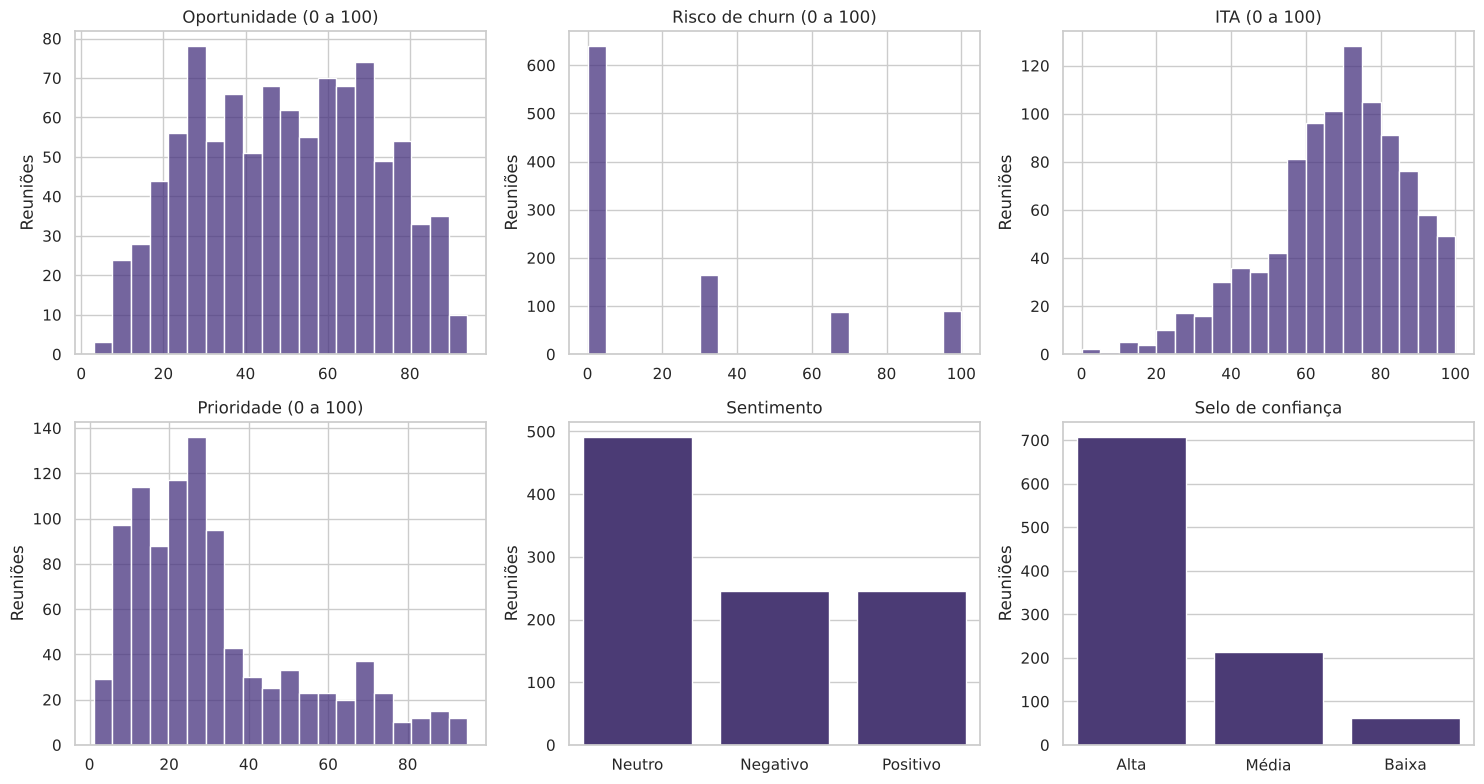

Faixa de oportunidade: [('Alta', 361), ('Baixa', 353), ('Média', 268)]
Nível de risco: [('Sem sinais', 639), ('Atenção', 253), ('Alto', 90)]
Faixa de prioridade: [('Baixa', 684), ('Média', 136), ('Alta', 104), ('Crítica', 58)]
Sentimento: [('Neutro', 491), ('Negativo', 246), ('Positivo', 245)]
Selo de confiança: [('Alta', 707), ('Média', 214), ('Baixa', 61)]
ITA médio: 68


In [16]:
def faixa_prioridade(prioridade):
    if prioridade >= 75:
        return 'Crítica'
    if prioridade >= 55:
        return 'Alta'
    if prioridade >= 35:
        return 'Média'
    return 'Baixa'


indice_oportunidade = list(modelo_final.classes_).index('Oportunidade')
indicadores = pd.DataFrame({
    'oportunidade': (100 * modelo_final.predict_proba(base['TEXTO_LIMPO'])[:, indice_oportunidade]).round(),
    'risco': medidas['sinais_churn'].apply(nota_risco),
    'ita': [round(np.mean(list(notas_ita(m).values()))) for _, m in medidas.iterrows()],
    'sentimento': medidas['sentimento'].apply(classe_sentimento),
    'selo': medidas['n_locutores'].apply(selo_confianca),
})
indicadores['prioridade'] = (0.62 * indicadores['risco'] + 0.38 * indicadores['oportunidade']).round()

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for eixo, coluna, titulo in [(ax[0, 0], 'oportunidade', 'Oportunidade (0 a 100)'),
                             (ax[0, 1], 'risco', 'Risco de churn (0 a 100)'),
                             (ax[0, 2], 'ita', 'ITA (0 a 100)'),
                             (ax[1, 0], 'prioridade', 'Prioridade (0 a 100)')]:
    sns.histplot(indicadores[coluna], bins=20, ax=eixo)
    eixo.set_title(titulo)
    eixo.set_xlabel('')
    eixo.set_ylabel('Reuniões')
for eixo, coluna, titulo in [(ax[1, 1], 'sentimento', 'Sentimento'), (ax[1, 2], 'selo', 'Selo de confiança')]:
    contagem = indicadores[coluna].value_counts()
    sns.barplot(x=contagem.index, y=contagem.values, ax=eixo)
    eixo.set_title(titulo)
    eixo.set_xlabel('')
    eixo.set_ylabel('Reuniões')
plt.tight_layout()
plt.show()

print('Faixa de oportunidade:', Counter(indicadores['oportunidade'].apply(faixa_oportunidade)).most_common())
print('Nível de risco:', Counter(indicadores['risco'].apply(nivel_risco)).most_common())
print('Faixa de prioridade:', Counter(indicadores['prioridade'].apply(faixa_prioridade)).most_common())
print('Sentimento:', Counter(indicadores['sentimento']).most_common())
print('Selo de confiança:', Counter(indicadores['selo']).most_common())
print('ITA médio:', round(indicadores['ita'].mean()))

A nota de oportunidade se espalha por toda a escala: 361 reuniões na faixa Alta, 268 na Média e 353 na Baixa. O risco fica em zero em 639 reuniões e só 90 (9%) chegam a 100; como a nota é a contagem de sinais dividida por 3, o histograma tem só quatro valores (0, 33, 67 e 100). O ITA médio é 68, e a maioria das reuniões fica entre 60 e 90. Na prioridade, 58 reuniões caem na faixa Crítica e 104 na Alta, que é o topo da fila do gestor. O sentimento fica com um quarto das reuniões em cada ponta, como a regra dos quartis define, e o selo de confiança é baixo em 61 reuniões.

Para conferir se os indicadores medem coisas diferentes, olhamos a correlação entre eles e o número de locutores.

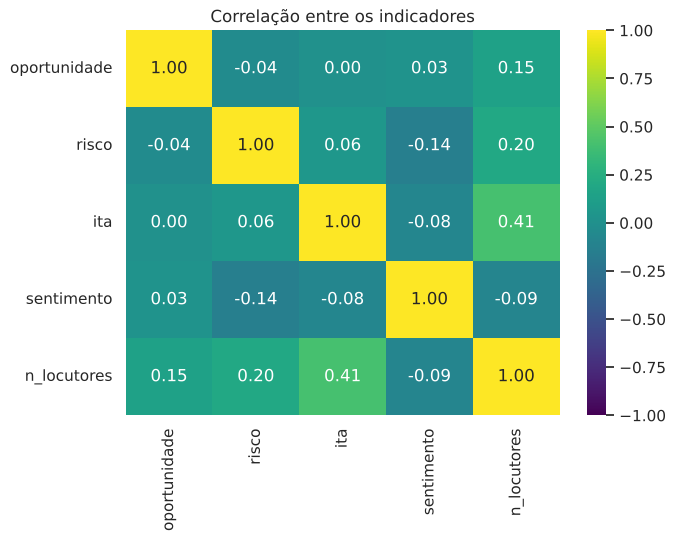

,oportunidade,risco,ita,sentimento,n_locutores
oportunidade,1.00,-0.04,0.00,0.03,0.15
risco,-0.04,1.00,0.06,-0.14,0.20
ita,0.00,0.06,1.00,-0.08,0.41
sentimento,0.03,-0.14,-0.08,1.00,-0.09
n_locutores,0.15,0.20,0.41,-0.09,1.00


In [17]:
correlacao = pd.concat([indicadores[['oportunidade', 'risco', 'ita']], medidas[['sentimento', 'n_locutores']]], axis=1).corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='viridis', vmin=-1, vmax=1)
plt.title('Correlação entre os indicadores')
plt.show()

correlacao.round(2)

Entre os quatro indicadores, nenhuma correlação passa de 0,14 em valor absoluto: cada um traz uma informação que os outros não trazem, e por isso o app mostra todos, e não um número único. A exceção está no número de locutores, que tem correlação de 0,41 com o ITA. Quanto mais fragmentada a transcrição, mais a fala parece dividida entre muitas pessoas, e o engajamento sobe sem a conversa ter sido melhor. É exatamente o problema que o selo de confiança existe para avisar.

---

## Parte 4 — Protótipo funcional

**Regras de recomendação.** A última etapa transforma os indicadores em uma ação, nesta ordem de prioridade:

1. Risco **Alto** → **Retenção**: acionar o gestor da conta e falar com o cliente em até 48 horas.
2. Oportunidade **Alta** → **Avançar a venda**: enviar proposta ou agendar demonstração dos produtos citados.
3. Risco **Atenção** com sentimento **Negativo** → **Cuidar do relacionamento** antes de oferecer algo novo.
4. Dois ou mais sinais de expansão → **Oferecer expansão**: módulos ou licenças a mais para o cliente.
5. Oportunidade **Média** → **Qualificar**: confirmar necessidade, prazo e orçamento.
6. Nenhuma das anteriores → **Acompanhar** no ciclo normal da conta.

A oportunidade alta vem antes da regra 3 porque, numa prospecção, o cliente falar de dificuldades ou de "outro fornecedor" não é risco para a TOTVS: é a dor que ele quer resolver e o sistema que usa hoje. A regra 4 cobre uma limitação que vimos na Sprint 3: o modelo separa prospecção de cliente da base, então um cliente atual pedindo mais módulos não aparece como oportunidade.

A ação vem acompanhada de avisos (concorrente citado, selo de confiança baixo e risco alto em reunião com cara de prospecção) e de um retorno sobre a condução, no mesmo formato do app: o critério do ITA com a menor nota, quando ela fica abaixo de 50.

In [18]:
DICAS_CONDUCAO = {
    'perguntas': 'Poucas perguntas de descoberta. Explore mais o contexto e as dores do cliente antes de apresentar a solução.',
    'balanco': 'A fala ficou concentrada em um interlocutor. Abra mais espaço para o cliente falar.',
    'engajamento': 'Pouca participação dos demais. Envolva as outras pessoas da reunião.',
    'proximos_passos': 'A conversa não fechou com próximos passos claros. Encerre com um compromisso e uma data.',
}


def gerar_recomendacao(r):
    produtos = ', '.join(r['produtos']) if r['produtos'] else 'a solução discutida'
    if r['nivel_risco'] == 'Alto':
        acao = 'Retenção: acionar o gestor da conta e agendar contato com o cliente em até 48 horas.'
    elif r['faixa_oportunidade'] == 'Alta':
        acao = 'Avançar a venda: enviar proposta ou agendar demonstração de ' + produtos + '.'
    elif r['nivel_risco'] == 'Atenção' and r['sentimento'] == 'Negativo':
        acao = 'Cuidar do relacionamento: retomar os pontos negativos antes de oferecer algo novo.'
    elif r['sinais_expansao'] >= 2:
        acao = 'Oferecer expansão: apresentar módulos ou licenças adicionais ao cliente.'
    elif r['faixa_oportunidade'] == 'Média':
        acao = 'Qualificar: confirmar necessidade, prazo e orçamento na próxima conversa.'
    else:
        acao = 'Acompanhar: manter o relacionamento no ciclo normal da conta.'

    avisos = []
    if r['nivel_risco'] == 'Alto' and r['faixa_oportunidade'] == 'Alta':
        avisos.append('A reunião também parece prospecção: confirme se a insatisfação é com a TOTVS ou com o fornecedor atual do cliente.')
    if r['concorrentes']:
        avisos.append('Concorrente citado (' + ', '.join(r['concorrentes']) + '): leve um comparativo para a próxima conversa.')
    if r['selo'] == 'Baixa':
        avisos.append('Selo de confiança baixo: confira a transcrição antes de agir.')
    return acao, avisos


def resumir(r):
    # mesma frase de abertura da tela de reunião do app
    partes = []
    if r['produtos']:
        partes.append('falou sobre ' + ', '.join(r['produtos'][:3]))
    if r['concorrentes']:
        partes.append('citou ' + ' e '.join(r['concorrentes']))
    if r['nivel_risco'] == 'Alto':
        partes.append('deu sinais de que pode cancelar')
    if r['faixa_oportunidade'] == 'Alta':
        partes.append('tem perfil de oportunidade de venda')
    if not partes:
        return 'Nesta conversa não apareceram sinais fortes de risco nem de oportunidade.'
    return 'Nesta conversa, o cliente ' + '; '.join(partes) + '.'

A função `analisar_reuniao` é a solução integrada: recebe o texto bruto e passa por todas as etapas. O parâmetro `modelo` permite usar outro modelo; na Parte 5 usamos o que treinou só com a parte de treino.

In [19]:
def analisar_reuniao(transcricao, modelo=modelo_final):
    # Processamento
    texto_limpo = pipeline_limpeza(transcricao)
    texto_busca = texto_para_busca(transcricao)
    conversa = medir_conversa(transcricao)

    # Modelo
    indice = list(modelo.classes_).index('Oportunidade')
    oportunidade = round(100 * modelo.predict_proba([texto_limpo])[0][indice])

    # Indicadores
    sinais = contar_termos(texto_busca, SINAIS_CHURN)
    risco = nota_risco(sum(sinais.values()))
    criterios = notas_ita(conversa)
    concorrentes = identificar(texto_busca, CONCORRENTES)

    r = {
        'produtos': identificar(texto_busca, PRODUTOS_TOTVS),
        'concorrentes': concorrentes,
        'trechos_concorrentes': [trecho(texto_busca, CONCORRENTES[c][0]) for c in concorrentes],
        'valores': valores_citados(transcricao),
        'sentimento': classe_sentimento(pontuar_sentimento(texto_busca)),
        'risco': risco,
        'nivel_risco': nivel_risco(risco),
        'sinais_churn': sinais,
        'trechos_churn': [trecho(texto_busca, s) for s in list(sinais)[:3]],
        'oportunidade': oportunidade,
        'faixa_oportunidade': faixa_oportunidade(oportunidade),
        'sinais_expansao': sum(contar_termos(texto_busca, SINAIS_EXPANSAO).values()),
        'prioridade': round(0.62 * risco + 0.38 * oportunidade),
        'ita': round(np.mean(list(criterios.values()))),
        'criterios_ita': criterios,
        'selo': selo_confianca(conversa['n_locutores']),
        'n_locutores': conversa['n_locutores'],
        'principais_termos': principais_termos(texto_limpo),
    }

    # Recomendação
    pior = min(criterios, key=criterios.get)
    r['conducao'] = DICAS_CONDUCAO[pior] if criterios[pior] < 50 else 'Boa condução: descoberta, equilíbrio de fala e encaminhamento presentes.'
    r['resumo'] = resumir(r)
    r['recomendacao'], r['avisos'] = gerar_recomendacao(r)
    return r


def exibir_relatorio(r):
    print('Resumo:', r['resumo'])
    print('Produto identificado:', ', '.join(r['produtos']) or 'nenhum')
    print('Concorrentes:', ', '.join(r['concorrentes']) or 'nenhum')
    print('Valores citados:', ', '.join(r['valores']) or 'nenhum')
    print('Sentimento:', r['sentimento'])
    print('Risco de churn:', r['risco'], 'de 100 -', r['nivel_risco'], r['sinais_churn'])
    for t in r['trechos_churn']:
        print('    ', t)
    print('Oportunidade comercial:', r['oportunidade'], 'de 100 -', r['faixa_oportunidade'])
    print('Prioridade:', r['prioridade'], 'de 100 -', faixa_prioridade(r['prioridade']))
    print('ITA:', r['ita'], 'de 100', {CRITERIOS_ITA[c]: v for c, v in r['criterios_ita'].items()})
    print('Condução:', r['conducao'])
    print('Selo de confiança:', r['selo'], '(' + str(r['n_locutores']) + ' locutores)')
    print('Principais termos:', ', '.join(r['principais_termos']))
    print('RECOMENDAÇÃO:', r['recomendacao'])
    for aviso in r['avisos']:
        print('  *', aviso)

**Demonstração.** Aplicamos a função à reunião com a maior nota de oportunidade e à reunião com mais sinais de churn da base.

In [20]:
reuniao_oportunidade = base.loc[indicadores.sort_values('oportunidade', ascending=False).index[0]]
print('Reunião', reuniao_oportunidade['ID_MEETING'], '-', reuniao_oportunidade['NOME_SEGMENTO'])
exibir_relatorio(analisar_reuniao(reuniao_oportunidade['TRANSCRICAO']))

Reunião 1028228 - Sem segmento
Resumo: Nesta conversa, o cliente falou sobre Protheus, Fluig; tem perfil de oportunidade de venda.
Produto identificado: Protheus, Fluig
Concorrentes: nenhum
Valores citados: R$ 1.000,00
Sentimento: Negativo
Risco de churn: 33 de 100 - Atenção {'outro fornecedor': 1}
     ...seja eu tenho um fornecedor que me entrega item a e c dai eu tenho outro fornecedor que me entrega esses mesmos quando eu for fazer uma compra que eu for gerar...
Oportunidade comercial: 94 de 100 - Alta
Prioridade: 56 de 100 - Alta
ITA: 49 de 100 {'Perguntas de descoberta': 60, 'Balanço de fala': 53, 'Engajamento da conversa': 57, 'Próximos passos definidos': 25}
Condução: A conversa não fechou com próximos passos claros. Encerre com um compromisso e uma data.
Selo de confiança: Alta (12 locutores)
Principais termos: estoque, paciente, entrada, controle, saldo, custo, visão, nota
RECOMENDAÇÃO: Avançar a venda: enviar proposta ou agendar demonstração de Protheus, Fluig.


In [21]:
reuniao_risco = base.loc[medidas.sort_values('sinais_churn', ascending=False).index[0]]
print('Reunião', reuniao_risco['ID_MEETING'], '-', reuniao_risco['NOME_SEGMENTO'])
exibir_relatorio(analisar_reuniao(reuniao_risco['TRANSCRICAO']))

Reunião 1291242 - SAUDE


Resumo: Nesta conversa, o cliente falou sobre Protheus, RM, Fluig; deu sinais de que pode cancelar.
Produto identificado: Protheus, RM, Fluig
Concorrentes: nenhum
Valores citados: nenhum
Sentimento: Neutro
Risco de churn: 100 de 100 - Alto {'cancelamento': 23, 'rescindir': 1, 'muito caro': 1}
     ...fluid e ai em nenhum momento eles disseram para mim abre um chamado e pede cancelamento em nenhum momento eles simplesmente disseram pode ficar tranquilo que eu vou a gente vai...
     ...decisoes e muito facil tomar uma decisao de assinar contrato e tem decisoes dificeis de rescindir o contrato faz parte do mundo de negocios e esta tudo certo o meu ponto...
     ...precisava parte do suporte que nao conseguiu ajudar a gente porque tudo a distancia ficaria muito caro se a gente tivesse um suporte presencial e voces sabem que muitas coisas que inviabilizam...
Oportunidade comercial: 25 de 100 - Baixa
Prioridade: 72 de 100 - Alta
ITA: 62 de 100 {'Perguntas de descoberta': 40, 'Balanço de fal

Lemos as duas transcrições para conferir. A 1028228 é uma demonstração do fluxo de compras e estoque (cotação, entrada de nota, produto por fornecedor). O modelo dá 94 de oportunidade e a recomendação é avançar a venda com Protheus e Fluig. O "outro fornecedor" que acendeu o sinal de risco é o fornecedor de mercadorias do próprio cliente, que é o motivo de a regra 2 vir antes da regra 3. O ITA de 49 mostra que a reunião terminou sem próximo passo claro, e o retorno de condução aponta exatamente isso.

A 1291242 é um cliente que abriu chamado de cancelamento e contesta seis meses a mais de cobrança. "Cancelamento" aparece 23 vezes, o risco chega a 100 e a recomendação é retenção. Os trechos mostram ao gestor onde está o problema sem ele precisar ler a reunião inteira.

**Tempo de processamento.** A TOTVS faz mais de 10 mil reuniões por mês, então medimos o tempo da função em 100 reuniões.

In [22]:
inicio = perf_counter()
for texto in base['TRANSCRICAO'].sample(100, random_state=SEMENTE):
    analisar_reuniao(texto)
tempo = (perf_counter() - inicio) / 100
print('Tempo médio por reunião:', round(tempo, 3), 's')
print('Estimativa para 10 mil reuniões:', round(tempo * 10000 / 60), 'minutos')

Tempo médio por reunião: 0.138 s
Estimativa para 10 mil reuniões: 23 minutos


**Arquivos para o app.** Como no CP05, salvamos com o `joblib` o modelo final, o TF-IDF dos principais termos e um dicionário com as referências e os dicionários de termos, para o app usar exatamente os mesmos valores. Também salvamos as duas reuniões da demonstração como exemplos e o resultado da reunião de oportunidade para o teste de paridade.

In [23]:
referencias = {
    'STOPWORDS_PT': STOPWORDS_PT, 'PRODUTOS_TOTVS': PRODUTOS_TOTVS, 'CONCORRENTES': CONCORRENTES,
    'SINAIS_CHURN': SINAIS_CHURN, 'SINAIS_EXPANSAO': SINAIS_EXPANSAO,
    'PALAVRAS_POSITIVAS': PALAVRAS_POSITIVAS, 'PALAVRAS_NEGATIVAS': PALAVRAS_NEGATIVAS,
    'PROXIMOS_PASSOS': PROXIMOS_PASSOS, 'CRITERIOS_ITA': CRITERIOS_ITA, 'DICAS_CONDUCAO': DICAS_CONDUCAO,
    'SENT_Q1': SENT_Q1, 'SENT_Q3': SENT_Q3, 'LIMITE_CHURN': LIMITE_CHURN,
    'REFERENCIA_ITA': REFERENCIA_ITA, 'Q3_LOCUTORES': q3_loc, 'LIMITE_OUTLIER': LIMITE_OUTLIER,
}
joblib.dump(modelo_final, 'modelo_oportunidade.joblib')
joblib.dump(tfidf_termos, 'tfidf_termos.joblib')
joblib.dump(referencias, 'referencias.joblib')

for nome, reuniao in [('exemplo_oportunidade.txt', reuniao_oportunidade), ('exemplo_risco.txt', reuniao_risco)]:
    with open(nome, 'w', encoding='utf-8') as f:
        f.write(reuniao['TRANSCRICAO'])

paridade = analisar_reuniao(reuniao_oportunidade['TRANSCRICAO'])
pd.DataFrame([{'arquivo': 'exemplo_oportunidade.txt', 'oportunidade': paridade['oportunidade'],
               'risco': paridade['risco'], 'ita': paridade['ita'], 'prioridade': paridade['prioridade'],
               'recomendacao': paridade['recomendacao']}]).to_csv('paridade.csv', index=False)
pd.read_csv('paridade.csv')

,arquivo,oportunidade,risco,ita,prioridade,recomendacao
0,exemplo_oportunidade.txt,94,33,49,56,"Avançar a venda: enviar proposta ou agendar demonstração de Protheus, Fluig."


**App em Streamlit.** O arquivo `app_bateia.py` carrega esses arquivos e repete as mesmas funções. O vendedor cola a transcrição (ou escolhe um dos exemplos) no formulário e recebe o resultado no mesmo formato da tela de reunião do Bateia. A seção "Teste de paridade" do app analisa o `exemplo_oportunidade.txt` e compara com o `paridade.csv`; os números têm que ser iguais aos do notebook. Para rodar: `streamlit run app_bateia.py`.

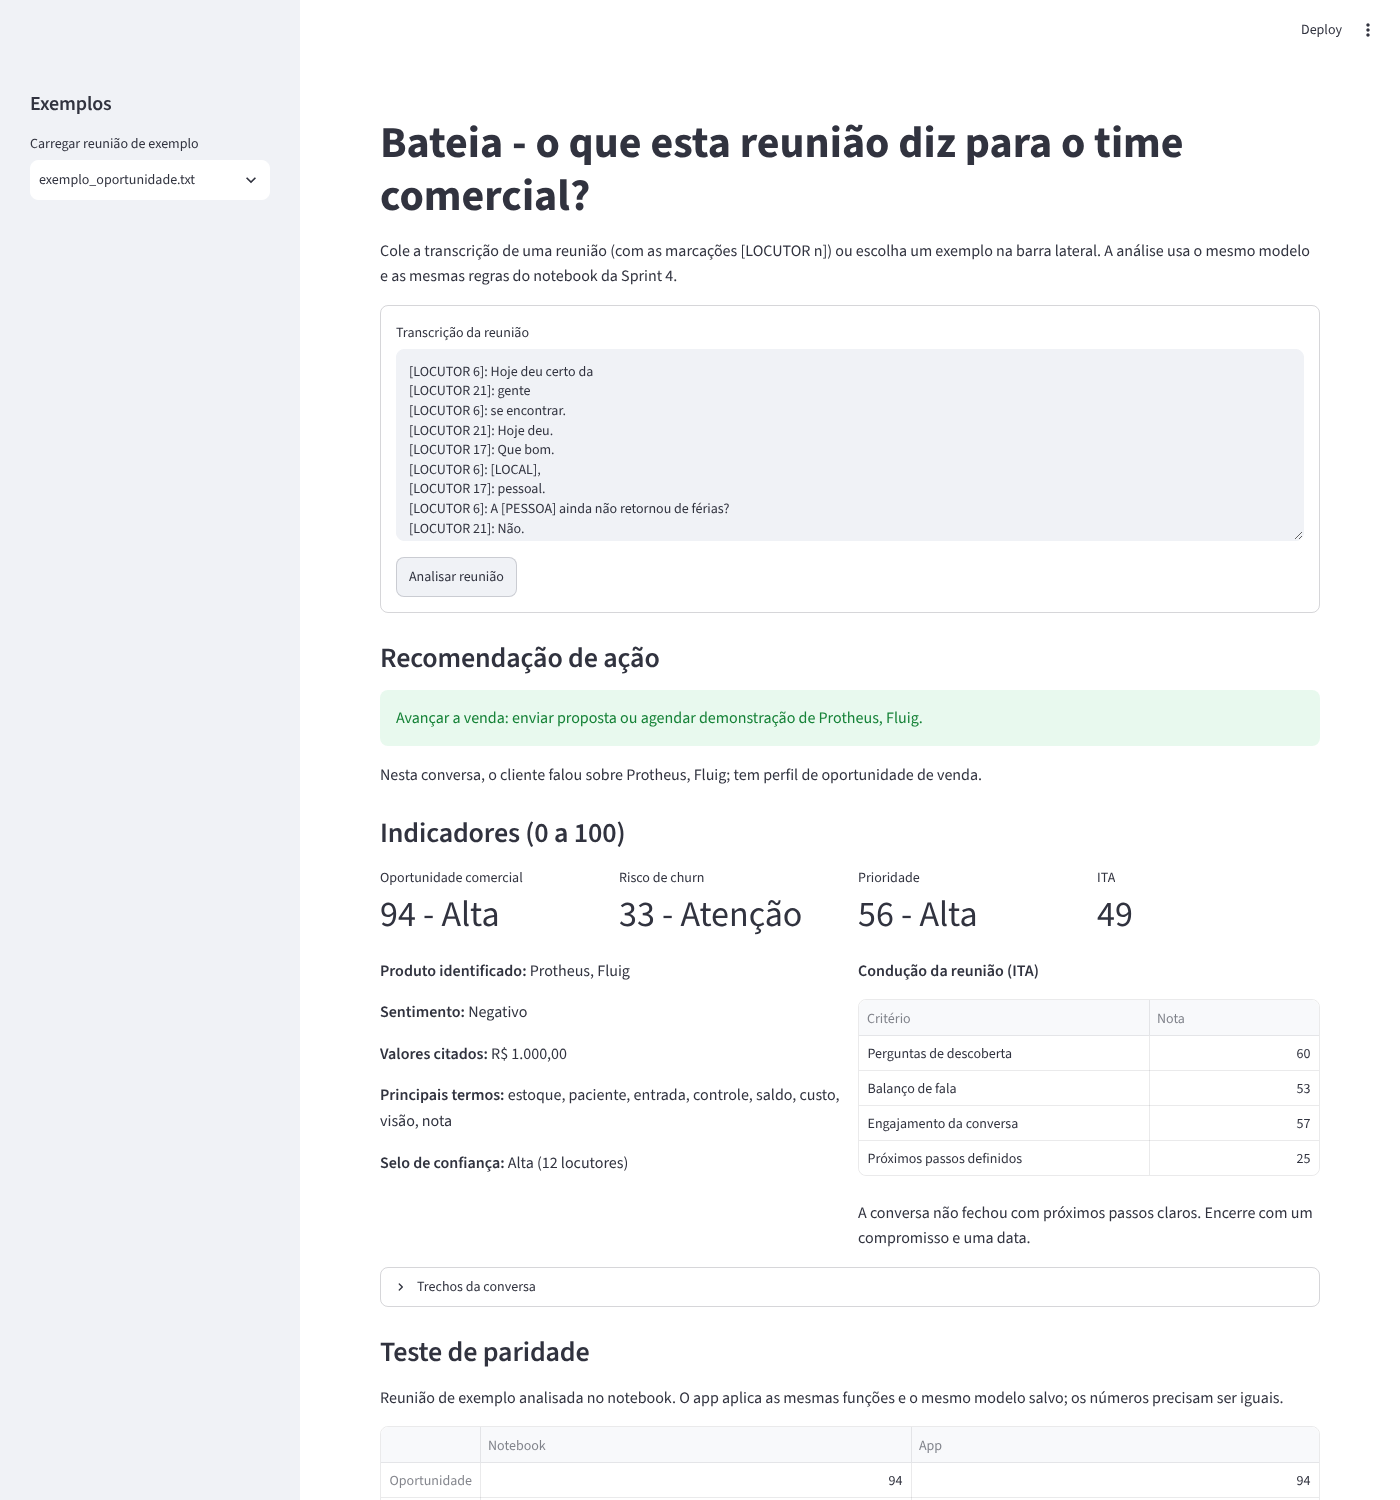

---

## Parte 5 — Validação com novas transcrições

Validamos a solução com quatro grupos de transcrições, cada um testando uma parte diferente.

### 5.1 Reuniões de teste: o fluxo completo contra o rótulo real

Aqui usamos, pela primeira e única vez, as 52 reuniões de teste que ficaram guardadas na Parte 2. Elas entram na forma bruta na `analisar_reuniao`, com o modelo treinado só com as 153 de treino. São as mesmas reuniões de teste da Sprint 3, então, se o pipeline estiver certo, o resultado tem que ser o mesmo da avaliação de lá (F1-macro de 0,606).

                  precision    recall  f1-score   support

Não oportunidade      0.645     0.690     0.667        29
    Oportunidade      0.571     0.522     0.545        23

        accuracy                          0.615        52
       macro avg      0.608     0.606     0.606        52
    weighted avg      0.613     0.615     0.613        52



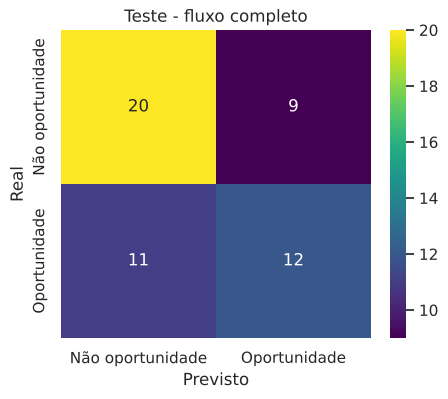

In [24]:
modelo_treino = montar_pipeline(criar_modelo('Regressão Logística')).fit(X_treino, y_treino)

teste = rotuladas.loc[X_teste.index].copy()
resultados_teste = [analisar_reuniao(t, modelo=modelo_treino) for t in teste['TRANSCRICAO']]
teste['nota'] = [r['oportunidade'] for r in resultados_teste]
teste['faixa'] = [r['faixa_oportunidade'] for r in resultados_teste]
teste['previsto'] = teste['nota'].apply(lambda n: 'Oportunidade' if n >= 50 else 'Não oportunidade')

print(classification_report(teste['oportunidade'], teste['previsto'], digits=3))

classes = ['Não oportunidade', 'Oportunidade']
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(teste['oportunidade'], teste['previsto'], labels=classes), annot=True,
            fmt='d', cmap='viridis', xticklabels=classes, yticklabels=classes)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Teste - fluxo completo')
plt.show()

O resultado é idêntico ao da Sprint 3: F1-macro de 0,606 e acurácia de 0,615. Isso confirma que o caminho completo dentro da função (texto bruto, limpeza, TF-IDF e modelo) reproduz o que foi avaliado. Das 23 oportunidades reais do teste o modelo marcou 12 (recall de 0,52), e das 21 reuniões que ele marcou como oportunidade, 12 eram de fato (precisão de 0,57).

As faixas de oportunidade também precisam fazer sentido: a faixa Alta tem que ter mais oportunidades reais do que a Baixa.

In [25]:
teste['eh_oportunidade'] = teste['oportunidade'] == 'Oportunidade'
por_faixa = teste.groupby('faixa')['eh_oportunidade'].agg(['size', 'sum', 'mean'])
por_faixa.columns = ['reuniões', 'oportunidades reais', '% de oportunidades']
por_faixa['% de oportunidades'] = (100 * por_faixa['% de oportunidades']).round()
por_faixa.reindex(['Alta', 'Média', 'Baixa'])

,reuniões,oportunidades reais,% de oportunidades
faixa,,,
Alta,13,8,62.0
Média,15,8,53.0
Baixa,24,7,29.0


Na faixa Alta, 62% das reuniões eram oportunidades reais; na Baixa, 29%; a Média fica no meio, com 53%. Mesmo errando parte dos casos, a nota ordena bem a fila: começar pelas reuniões da faixa Alta dá mais que o dobro de chance de encontrar uma oportunidade do que começar pelas da Baixa.

### 5.2 Reuniões sem rótulo

São as reuniões em que o CRM não tem o `TP_RECURSO`, ou seja, o caso real de uso. Não há resposta para conferir, então olhamos o comportamento: a função tem que rodar em todas, as faixas têm que se distribuir de forma razoável e as reuniões mais bem colocadas têm que tratar de assuntos de venda. Aplicamos a função às 982 reuniões de uma vez (o resultado é usado de novo na Parte 6) e separamos as sem rótulo.

In [26]:
resultados = pd.DataFrame([analisar_reuniao(t) for t in base['TRANSCRICAO']])
resultados['ID_MEETING'] = base['ID_MEETING']
resultados['CODT'] = base['CODT']
resultados['NOME_SEGMENTO'] = base['NOME_SEGMENTO']
resultados['rotulo'] = base['oportunidade']

novas = resultados[resultados['rotulo'].isna()]
print('Reuniões sem rótulo processadas:', len(novas))
for coluna in ['faixa_oportunidade', 'nivel_risco', 'sentimento', 'selo']:
    print(coluna, Counter(novas[coluna]).most_common())
print()
for _, r in novas.sort_values('oportunidade', ascending=False).head(5).iterrows():
    print(r['ID_MEETING'], r['NOME_SEGMENTO'], '| oportunidade', r['oportunidade'], '|', ', '.join(r['principais_termos'][:6]))

Reuniões sem rótulo processadas: 777
faixa_oportunidade [('Alta', 277), ('Média', 250), ('Baixa', 250)]
nivel_risco [('Sem sinais', 503), ('Atenção', 205), ('Alto', 69)]
sentimento [('Neutro', 380), ('Negativo', 201), ('Positivo', 196)]
selo [('Alta', 569), ('Média', 186), ('Baixa', 22)]

1028228 Sem segmento | oportunidade 94 | estoque, paciente, entrada, controle, saldo, custo
1333111 Sem segmento | oportunidade 93 | estoque, operação, nota, paciente, produção, venda
1015499 Sem segmento | oportunidade 92 | item, estoque, compra, caixa, controle, simples
1198977 Sem segmento | oportunidade 90 | pedido, portal, venda, preço, compra, compras
1157310 Sem segmento | oportunidade 90 | paciente, nota fiscal, fiscal, nota, integração, médico


A função rodou nas 777 reuniões sem erro, e as proporções de faixa de oportunidade, risco e sentimento são parecidas com as da base inteira (Parte 3). As cinco reuniões com maior nota falam de estoque, compras, pedidos, produção e nota fiscal, que é o assunto de quem está avaliando um ERP. Todas estão sem segmento no cadastro, o que é comum em prospecção: quem ainda não é cliente costuma ter o cadastro incompleto.

### 5.3 Base simulada do Challenge

O arquivo `reunioes_transcricoes_mockado.csv` tem 500 linhas no formato completo do dicionário de dados, inclusive a `NOTA_NPS`, que não existe na base real. Antes de usar o NPS para validar o sentimento, conferimos o conteúdo.

In [27]:
mock = pd.read_csv('reunioes_transcricoes_mockado.csv')
print('Linhas:', len(mock), '| transcrições diferentes:', len(mock['ANON_TRANSCRICAO'].unique()))
mock['inicio_do_texto'] = mock['ANON_TRANSCRICAO'].apply(lambda t: t[:50])
mock.groupby('inicio_do_texto')['NOTA_NPS'].agg(['size', 'min', 'mean', 'max']).round(1)

Linhas: 500 | transcrições diferentes: 4


,size,min,mean,max
inicio_do_texto,,,,
[LOCUTOR 1]: A nossa solução conecta todas as loja,130,0,5.0,10
[LOCUTOR 1]: Boa tarde! Obrigado por vir.\n[LOCUTOR,120,0,5.0,10
[LOCUTOR 1]: Qual é o preço?\n[LOCUTOR 2]: Trabalha,137,0,4.9,10
[LOCUTOR 1]: Vocês querem fazer um teste?\n[LOCUTOR,113,0,4.8,10


As 500 linhas repetem só quatro textos, e o mesmo texto aparece com NPS de 0 a 10, com média perto de 5 nos quatro. O NPS dessa base foi sorteado sem relação com a conversa, então não serve para validar sentimento nem churn. O que ela permite é testar a solução em transcrições curtas, escritas de outro jeito, que o modelo nunca viu.

In [28]:
for texto in mock['ANON_TRANSCRICAO'].unique():
    r = analisar_reuniao(texto)
    print(texto.split('\n')[0][:60], '| oportunidade', r['oportunidade'], r['faixa_oportunidade'],
          '| risco', r['risco'], '| ITA', r['ita'], r['criterios_ita'], '|', r['recomendacao'].split(':')[0])

[LOCUTOR 1]: A nossa solução conecta todas as lojas em uma p | oportunidade 21 Baixa | risco 0 | ITA 69 {'perguntas': 100, 'balanco': 100, 'engajamento': 77, 'proximos_passos': 0} | Acompanhar
[LOCUTOR 1]: Boa tarde! Obrigado por vir. | oportunidade 33 Baixa | risco 0 | ITA 60 {'perguntas': 100, 'balanco': 81, 'engajamento': 59, 'proximos_passos': 0} | Acompanhar
[LOCUTOR 1]: Qual é o preço? | oportunidade 50 Média | risco 0 | ITA 72 {'perguntas': 100, 'balanco': 100, 'engajamento': 86, 'proximos_passos': 0} | Qualificar
[LOCUTOR 1]: Vocês querem fazer um teste? | oportunidade 47 Média | risco 0 | ITA 72 {'perguntas': 100, 'balanco': 100, 'engajamento': 86, 'proximos_passos': 0} | Qualificar


A função rodou sem nenhum ajuste e o resultado combina com o conteúdo: as conversas sobre preço e sobre teste e proposta ficam na faixa Média e recebem "Qualificar"; as duas de apresentação ficam na faixa Baixa. Aparecem também dois limites. A nota de oportunidade fica entre 21 e 50, porque textos de 8 falas têm poucos termos do vocabulário que o modelo aprendeu em reuniões de uma hora. E os próximos passos ficam em zero nas quatro, porque os últimos 20% de uma conversa de 8 falas são pouco mais de uma fala, e o "vou enviar a proposta" ficou antes dela.

### 5.4 Trechos anotados pelo grupo

Três de nós (Enzo, Gustavo e Rafaell) lemos 40 trechos cada de reuniões reais e marcamos cada um como **risco**, **neutro** ou **?** (não dá para saber). Um trecho ficou sem resposta e foi contado como "?". Usamos essa anotação para conferir o alerta de churn e o sentimento contra a leitura humana.

In [29]:
anotacao = pd.read_csv('anotacao_120_trechos.csv', encoding='latin1', sep=';')
anotacao['resposta'] = anotacao['SUA RESPOSTA'].apply(lambda v: v if isinstance(v, str) else '?')
anotacao['texto_busca'] = anotacao['Trecho da conversa'].apply(lambda t: texto_para_busca(str(t)))
anotacao['sinais'] = anotacao['texto_busca'].apply(lambda t: contar_termos(t, SINAIS_CHURN))
anotacao['alerta'] = anotacao['sinais'].apply(lambda s: 'com sinal' if s else 'sem sinal')
anotacao['sentimento'] = anotacao['texto_busca'].apply(pontuar_sentimento)

display(anotacao.groupby(['resposta', 'alerta']).size().to_frame('trechos'))
display(anotacao.groupby('resposta')['sentimento'].agg(['size', 'mean']).round(2))

trechos
resposta alerta            
?        com sinal        2
         sem sinal       21
neutro   com sinal        6
         sem sinal       86
risco    sem sinal        5

,size,mean
resposta,,
?,23,-0.07
neutro,92,-0.15
risco,5,-0.20


In [30]:
print('Trechos marcados como risco pelo grupo:')
for t in anotacao[anotacao['resposta'] == 'risco']['Trecho da conversa']:
    print('  ', t[:200], '...')
print()
print('Trechos em que o alerta encontrou sinal:')
for _, r in anotacao[anotacao['alerta'] == 'com sinal'].iterrows():
    print('  [' + r['resposta'] + ']', r['sinais'], trecho(r['texto_busca'], list(r['sinais'])[0]))

Trechos marcados como risco pelo grupo:
   gente não teve em nenhum momento sem demanda. Na verdade, a nossa principal queixa é justamente a amorosidade, a demora gigantesca nas entregas, e agora acabamos descobrindo que nossas horas não foram ...
   tem muita coisa assim. Esse atravessador tem casos que ele tem equipe que fazem a colheta da erva mate. às vezes no ponta corrente nós fizemos o pagamento para duas, a mesma erva. Às vezes ela é paga  ...
   sei porDeisi [LOCAL] e que tanta resistência. Só um pouquinho, aqui eu vou equalizar porque tá uma bagunça. Eu tenho mais de 50 projetos com TOTUS. Eu só quero deixar claro uma coisinha. A TOTUS é um  ...
   cancela ela, aumenta uma tamanho da outra, por exemplo. Então, tem isso, tá? Se eu for ligar para a Cláudia de vocês, no caso, eu teria que pegar aquela VM, deduzir ela para manter o curso de vendas l ...
   favor. Aí, tem esses pontos, tem a questão parcelamento reembolso, é a mesma coisa de reembolso do plano de saúde, o cara tev

Nenhum dos 5 trechos que marcamos como risco acendeu o alerta. Eles falam de queixa com a demora nas entregas, de resistência ao projeto, de cancelar uma máquina virtual para cortar custo, de pagamento em duplicidade e de funções que o sistema atual não conseguiu atender. O risco aparece no jeito de contar o problema, e não em palavras fixas.

Dos 8 trechos em que o alerta encontrou sinal, a maioria foi alarme falso: "cancelamento" de nota fiscal, de agendamento e de cobrança, e "concorrente" no sentido da concorrência do próprio cliente. Em dois casos, porém, o alerta viu algo que nós deixamos passar: trechos que marcamos como neutros falam em "processo de cancelamento do contrato" e em "não renovar" a manutenção.

O sentimento vai na direção esperada (a média dos trechos de risco, -0,20, é a mais negativa), mas a diferença é pequena e são só 5 trechos.

Não colocamos as palavras desses 5 trechos no dicionário: o alerta passaria a acertar esta anotação só por ter sido ajustado a ela, sem dizer nada sobre reuniões novas. A conclusão é que o alerta de churn por dicionário serve para apontar reuniões que vale a pena ler, e não para afirmar que o cliente vai cancelar. Um indicador confiável precisa de um rótulo real de churn (Parte 7).

**Resumo da validação.** O fluxo completo reproduz a avaliação do modelo e a nota de oportunidade ordena bem a fila (5.1). A solução roda em reuniões reais sem rótulo e em transcrições de outro formato (5.2 e 5.3). O alerta de churn não passou na comparação com a nossa leitura e o sentimento teve um resultado fraco (5.4). O ITA não tem nenhuma referência externa na base para ser validado.

---

## Parte 6 — Recomendações de negócio

Com a solução aplicada às 982 reuniões, olhamos o que a área comercial receberia hoje.

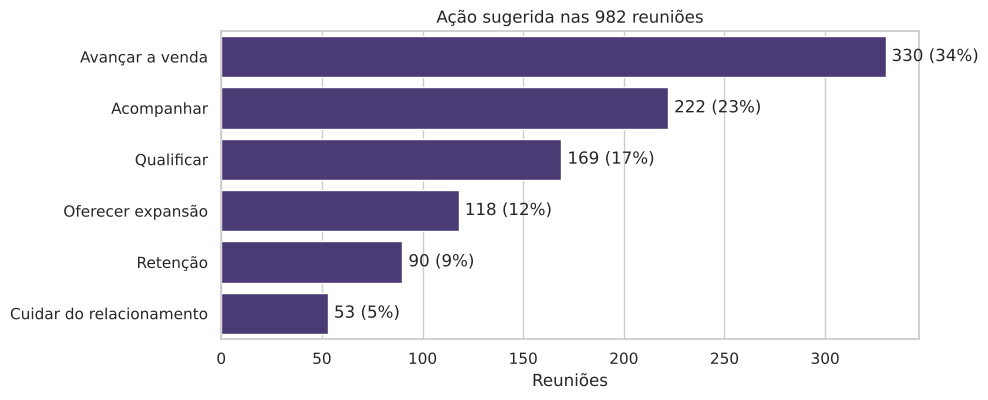

In [31]:
resultados['acao'] = resultados['recomendacao'].apply(lambda t: t.split(':')[0])
acoes = resultados['acao'].value_counts()

plt.figure(figsize=(9, 4))
sns.barplot(x=acoes.values, y=acoes.index)
for i, v in enumerate(acoes.values):
    plt.text(v + 3, i, str(v) + ' (' + str(round(100 * v / len(resultados))) + '%)', va='center')
plt.title('Ação sugerida nas 982 reuniões')
plt.xlabel('Reuniões')
plt.ylabel('')
plt.show()

A ação mais comum é "Avançar a venda", com 330 reuniões (34%). É uma fila grande, então dentro dela o vendedor deve começar pelas de maior nota de oportunidade. "Retenção" fica com 90 reuniões, as 9% com mais sinais de churn, e "Oferecer expansão" traz 118 reuniões que o modelo sozinho não marcaria.

Nas 205 reuniões rotuladas dá para ver para quem cada ação foi. O modelo já viu essas reuniões no treino, então as ações que dependem dele aparecem melhores do que seriam em reuniões novas; o que interessa aqui são as ações que vêm das regras.

In [32]:
resultados[resultados['rotulo'].notna()].groupby(['acao', 'rotulo']).size().to_frame('reuniões')

reuniões
acao                     rotulo                    
Acompanhar               Não oportunidade        57
                         Oportunidade             2
Avançar a venda          Não oportunidade         2
                         Oportunidade            75
Cuidar do relacionamento Não oportunidade        10
                         Oportunidade             1
Oferecer expansão        Não oportunidade        23
                         Oportunidade             2
Qualificar               Não oportunidade        10
                         Oportunidade             2
Retenção                 Não oportunidade        14
                         Oportunidade             7

"Oferecer expansão" foi para 23 clientes da base e só 2 prospecções, que era exatamente o caso que a regra queria recuperar. Já "Retenção" aparece em 7 prospecções, um terço das 21 reuniões rotuladas com essa ação. Lendo algumas delas, os sinais falam do fornecedor que o cliente usa hoje ("eles cobram muito caro") ou da concorrência no mercado do próprio cliente. Por isso a retenção vem com um aviso quando a reunião também tem cara de prospecção.

**Carteira de clientes.** Como no painel do gestor do app, agrupamos as reuniões por cliente (`CODT`) e ordenamos pela maior prioridade.

In [33]:
com_cliente = resultados[resultados['CODT'] != ''].copy()
com_cliente['risco_alto'] = com_cliente['nivel_risco'] == 'Alto'
por_cliente = com_cliente.groupby('CODT')
carteira = pd.DataFrame({
    'reuniões': por_cliente.size(),
    'prioridade': por_cliente['prioridade'].max(),
    'risco máximo': por_cliente['risco'].max(),
    'oportunidade máxima': por_cliente['oportunidade'].max(),
    'reuniões com risco alto': por_cliente['risco_alto'].sum(),
    'segmento': com_cliente.drop_duplicates('CODT').set_index('CODT')['NOME_SEGMENTO'],
})
carteira['faixa'] = carteira['prioridade'].apply(faixa_prioridade)
print('Clientes:', len(carteira))
print(Counter(carteira['faixa']).most_common())
carteira.sort_values(['prioridade', 'reuniões com risco alto'], ascending=False).head(10)

Clientes: 481
[('Baixa', 280), ('Média', 81), ('Alta', 73), ('Crítica', 47)]


,reuniões,prioridade,risco máximo,oportunidade máxima,reuniões com risco alto,segmento,faixa
CODT,,,,,,,
DBMVZM,1,95,100,88,1,Sem segmento,Crítica
TFEHER,12,94,100,83,2,MANUFATURA,Crítica
DBMSCI,2,94,100,84,1,Sem segmento,Crítica
CXHCWK,2,93,100,82,1,Sem segmento,Crítica
DBMHFO,1,93,100,81,1,Sem segmento,Crítica
118588,100,92,100,94,5,Sem segmento,Crítica
T09256,4,92,100,79,2,MANUFATURA,Crítica
TFDTYG,5,91,100,85,3,SERVICOS,Crítica
CXDMBT,3,91,100,76,1,Sem segmento,Crítica


Dos 481 clientes, 47 ficam na faixa Crítica e 73 na Alta. O topo da lista tem um padrão: clientes com risco 100 e oportunidade alta ao mesmo tempo. A fórmula do app soma as duas notas, então um cliente que reclama e ao mesmo tempo negocia algo novo sobe para o topo; é justamente o caso em que o aviso de prospecção ajuda o gestor a entender qual das duas coisas está acontecendo. O cliente 118588 reúne 100 reuniões, muito acima dos outros, o que sugere um código de cadastro genérico; vale confirmar com a TOTVS antes de agir sobre ele.

Por segmento (só os que têm pelo menos 15 reuniões):

In [34]:
tamanho = resultados['NOME_SEGMENTO'].value_counts()
por_segmento = resultados.groupby('NOME_SEGMENTO')[['oportunidade', 'risco', 'ita', 'prioridade']].mean().round(1)
por_segmento['reuniões'] = tamanho
por_segmento[por_segmento['reuniões'] >= 15].sort_values('risco', ascending=False)

,oportunidade,risco,ita,prioridade,reuniões
NOME_SEGMENTO,,,,,
EDUCACIONAL,49.8,26.0,73.6,35.1,32
MANUFATURA,44.9,25.3,66.4,32.7,187
VAREJO,46.1,24.1,70.9,32.4,29
SERVICOS,51.7,23.1,71.1,34.0,163
SAUDE,40.0,18.6,68.6,26.7,186
Sem segmento,57.1,17.2,66.2,32.3,353


Educacional e Manufatura têm o maior risco médio (26 e 25), e Saúde e as reuniões sem segmento, o menor (19 e 17). As reuniões sem segmento têm a maior nota média de oportunidade (57), o que é coerente com prospecção. O ITA fica perto de 70 em todos os segmentos.

### Recomendações para a área comercial

**1. Ordenar a fila do vendedor pela nota de oportunidade.** 79% das reuniões não têm o `TP_RECURSO` no CRM e hoje não recebem classificação nenhuma. No teste, a faixa Alta teve 62% de oportunidades reais, contra 29% na Baixa, então começar pelo topo da fila economiza tempo do time.

**2. Usar o alerta de churn como fila de leitura.** A validação mostrou que o alerta não reconhece risco com segurança. O gestor da conta deve ler as 90 reuniões com risco Alto, começando pelos clientes que repetem o alerta, antes de qualquer ação de retenção. Os trechos que a solução mostra encurtam essa leitura.

**3. Levar o ITA para o coaching, não para a avaliação.** O retorno de condução diz ao vendedor qual critério puxou a nota para baixo. Como o índice não foi comparado com resultado de venda, ele deve orientar conversas de desenvolvimento, e não metas ou remuneração.

**4. Mostrar sempre o selo de confiança.** Reuniões com selo baixo têm a fala dividida em dezenas de locutores, e o ITA dessas reuniões não é confiável. O selo deve aparecer ao lado de todos os indicadores, como já acontece no app.

**5. Aproveitar os sinais de expansão.** Clientes atuais pedindo módulos ou licenças não aparecem como oportunidade no modelo. A ação "Oferecer expansão" leva essas reuniões ao time de contas, que hoje não as veria.

**6. Não criar ação contra um concorrente específico.** Com a busca corrigida, concorrentes quase não são citados. Não há base para o alerta especial de SAP que a Sprint 2 sugeria.

---

## Parte 7 — Limitações e próximos passos

- **O rótulo classifica o cliente, não a reunião.** `lead` e `customer` dizem se a empresa já é cliente. O modelo separa prospecção de relacionamento, mas não mede diretamente a chance de fechar negócio.
- **Poucas reuniões rotuladas.** São 205, e o teste tem só 52. Na Sprint 3, só trocar a semente do sorteio já mudou o F1-macro do teste de 0,56 para 0,69.
- **O modelo aprende o segmento.** Termos como "paciente" e "contabilidade" pesam na decisão; parte da nota vem do setor do cliente, e não da conversa.
- **Não há rótulo de churn nem NPS real.** O risco e o sentimento são regras, e a comparação com a nossa anotação foi fraca.
- **O ITA não foi validado.** Os quatro critérios com o mesmo peso são uma escolha nossa, não um ajuste aos dados.
- **Qualidade da transcrição.** Há reuniões com até 179 locutores e 41 sem nenhuma marcação; balanço de fala e engajamento ficam distorcidos e o selo apenas avisa.
- **Dicionários escritos à mão.** Expressões fora da lista passam despercebidas, como mostrou a anotação.

**Próximos passos**

1. Pedir à TOTVS o histórico de cancelamentos e a nota NPS das contas. Com isso, o risco de churn vira um modelo supervisionado, treinado do mesmo jeito que o de oportunidade, e o sentimento pode ser comparado com a satisfação declarada.
2. Registrar no CRM se a reunião gerou proposta, para ter um rótulo da reunião, e não só do cliente.
3. Anotar mais trechos de risco e usar uma parte separada para testar, antes de ampliar os sinais de churn.
4. Retreinar o modelo conforme o CRM ganhar novas reuniões rotuladas, acompanhando o F1-macro e o recall de oportunidade.
5. Comparar o ITA dos vendedores com a taxa de conversão das oportunidades, quando esse dado existir.
6. Usar a `analisar_reuniao` para gerar o arquivo de dados do app Bateia, no lugar das regras das Sprints 1 e 2 que geram os dados hoje.

### Síntese da solução

**Problema e base.** Receber a transcrição de uma reunião comercial e devolver produto, sentimento, risco de churn, oportunidade comercial, principais termos e recomendação de ação. Base de 982 transcrições reais da TOTVS, 205 com rótulo do CRM.

**Pipeline.** A limpeza da Sprint 1, os dicionários da Sprint 2 revisados (acentos, palavra inteira e termos genéricos) e a medição da conversa pelas marcações de locutor, tudo dentro da função `analisar_reuniao`.

**Modelo final.** Regressão Logística com TF-IDF e `C=5`, escolhida por validação cruzada só no treino. Empatou com o Random Forest no F1-macro (0,678 contra 0,676), mas encontra mais oportunidades reais, é mais estável entre os folds e explica a decisão pelos coeficientes.

**Indicadores.** Oportunidade, risco de churn, ITA e prioridade de 0 a 100, sentimento em três classes e selo de confiança, todos com referências tiradas da própria base (quartis, percentil 90 e limite de outlier) e nas mesmas escalas do app Bateia.

**Protótipo.** Função `analisar_reuniao`, arquivos salvos com `joblib` e app em Streamlit com teste de paridade. Pouco mais de um décimo de segundo por reunião, ou cerca de 20 minutos para 10 mil reuniões.

**Validação.** O fluxo completo reproduz o F1-macro de 0,606 da Sprint 3; a faixa Alta tem 62% de oportunidades reais contra 29% da Baixa; a solução roda em 777 reuniões sem rótulo e em transcrições simuladas. O alerta de churn não reconheceu os 5 trechos de risco anotados pelo grupo.

**Negócio.** A fila do vendedor é ordenada pela nota de oportunidade, o alerta de churn vira fila de leitura para o gestor, o ITA vai para o coaching e os sinais de expansão levam clientes atuais ao time de contas.

Repositório: https://github.com/RafaellSantiagoMS/Bateia_Sprint4_DataScience

---

## Referências

* GÉRON, Aurélien. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. 3. ed. Sebastopol: O'Reilly Media, 2023.

* JURAFSKY, Daniel; MARTIN, James H. *Speech and Language Processing*. 3. ed. (rascunho), 2024. Capítulos sobre TF-IDF, regressão logística e léxicos de sentimento.

* PEDREGOSA, Fabian et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825–2830, 2011.